# MNIST — Softmax Regression cài tay và scikit-learn

Đặt `softmax.py` tại `src/softmax.py`, notebook tại `notebooks/softmax.ipynb`. Giữ `src/data.py` và `src/config.py` hiện có. Cũng có thể đặt notebook ở thư mục gốc. 

In [1]:
from pathlib import Path
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, log_loss
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong project chứa src/data.py và src/config.py.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
from src.models.softmax import SoftmaxRegression
print('scikit-learn:', sklearn.__version__)


scikit-learn: 1.9.1


## 1. Dữ liệu và cách so sánh

`load_prepared_mnist()` đã flatten, chia 255 và one-hot: không chuẩn hóa lần nữa. Đổi nhãn về số nguyên cho scikit-learn và phân tầng.

Giữ nguyên 10.000 ảnh test chính thức; chia 60.000 ảnh train thành 54.000 train / 6.000 validation. Chỉ dùng validation để chọn checkpoint và điều chỉnh siêu tham số. Không dùng test để chọn mô hình.


In [2]:
SEED = 42
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Nhãn train:', y_train.shape)
print('Miền pixel:', X_train.min(), X_train.max())

Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)
Nhãn train: (50000,)
Miền pixel: 0.0 1.0


In [3]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape, y_train.dtype)
print("y_train mẫu:", y_train[:3])

print("X_val:", X_val.shape)
print("y_val:", y_val.shape, y_val.dtype)

X_train: (50000, 784)
y_train: (50000,) uint8
y_train mẫu: [7 1 9]
X_val: (10000, 784)
y_val: (10000,) uint8


## 2. Mô hình và gradient

Với $B$ ảnh trong một batch: $X\in\mathbb{R}^{B\times784}$, $W\in\mathbb{R}^{784\times10}$, $b\in\mathbb{R}^{10}$.

$$Z=XW+b,\qquad P_{ik}=\frac{e^{Z_{ik}-m_i}}{\sum_j e^{Z_{ij}-m_i}},\quad m_i=\max_j Z_{ij}.$$

$$J=-\frac1B\sum_i\log P_{i,y_i}+\frac\lambda2\|W\|_F^2,$$
$$\nabla_W J=\frac{X^T(P-Y)}B+\lambda W,\qquad \nabla_b J=\frac1B\sum_i(P_i-Y_i).$$

Cập nhật $W\leftarrow W-\eta\nabla_WJ$, tương tự cho $b$. Trong code, trừ 1 tại cột nhãn đúng tương đương trừ one-hot $Y$.

Chọn `C=1.0` cho thư viện và `l2=1/(C*N_train)` cho bản tay: cùng mục tiêu mean CE + L2, bias không bị phạt. Bản tay dùng mini-batch SGD; thư viện dùng L-BFGS. Đây là so sánh hai cách triển khai/tối ưu cùng mô hình, không phải phép đo tốc độ hai thuật toán giống nhau. Loss vẽ bên dưới là CE **chưa cộng L2**.


In [4]:
C = 1.0
manual = SoftmaxRegression(learning_rate=0.1, epochs=100, batch_size=256,
                           l2=1.0 / (C * len(X_train)), random_state=SEED, patience=15)
t0 = time.perf_counter()
manual.fit(X_train, y_train, X_val, y_val)
manual_time = time.perf_counter() - t0
print(f'Thời gian bản tay: {manual_time:.2f}s; đã chạy {manual.n_iter_} epochs')
print('Checkpoint có validation CE thấp nhất:', manual.best_epoch_)


Epoch   1 | train CE=0.4925 | acc=0.8774 | val CE=0.4981
Epoch  10 | train CE=0.3137 | acc=0.9127 | val CE=0.3268
Epoch  20 | train CE=0.2897 | acc=0.9191 | val CE=0.3071
Epoch  30 | train CE=0.2785 | acc=0.9221 | val CE=0.2993
Epoch  40 | train CE=0.2707 | acc=0.9250 | val CE=0.2940
Epoch  50 | train CE=0.2663 | acc=0.9260 | val CE=0.2920
Epoch  60 | train CE=0.2621 | acc=0.9268 | val CE=0.2892
Epoch  70 | train CE=0.2591 | acc=0.9280 | val CE=0.2877
Epoch  80 | train CE=0.2566 | acc=0.9289 | val CE=0.2874
Epoch  90 | train CE=0.2545 | acc=0.9293 | val CE=0.2863
Epoch 100 | train CE=0.2526 | acc=0.9299 | val CE=0.2857
Thời gian bản tay: 11.41s; đã chạy 100 epochs
Checkpoint có validation CE thấp nhất: 96


In [5]:
reference = LogisticRegression(C=C, solver='lbfgs', max_iter=1000, tol=1e-6)
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ConvergenceWarning)
    reference.fit(X_train, y_train)
reference_time = time.perf_counter() - t0
convergence_warnings = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
print(f'Thời gian thư viện: {reference_time:.2f}s; iterations: {reference.n_iter_}')
for message in convergence_warnings:
    print('CẢNH BÁO HỘI TỤ:', message)
print('Validation accuracy:', reference.score(X_val, y_val))


Thời gian thư viện: 700.10s; iterations: [591]
Validation accuracy: 0.9217


## 3. Đường học và đánh giá

Mỗi epoch SGD gồm nhiều lần cập nhật batch; một iteration L-BFGS có ý nghĩa khác. Không so trực tiếp hai số này. Thời gian bản tay bao gồm tính metric mỗi epoch và lựa chọn checkpoint; thư viện không có cùng chi phí theo dõi.


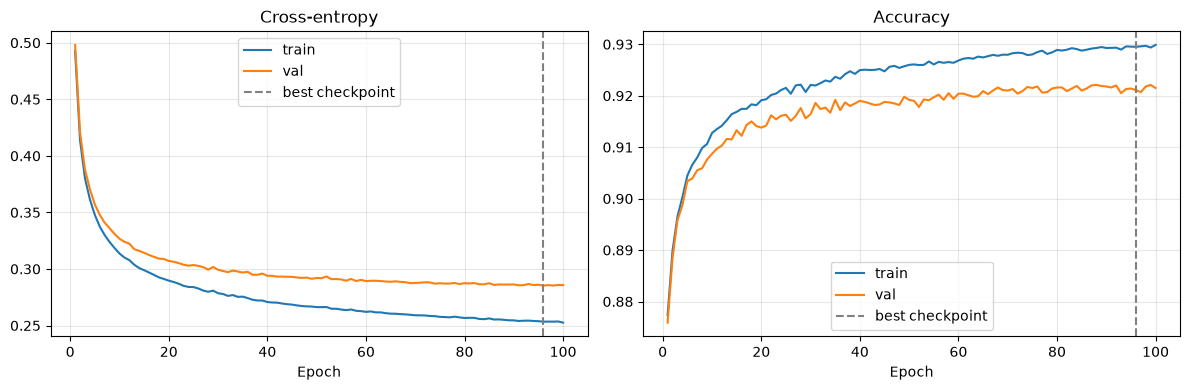

In [6]:
h = manual.history_
epochs = np.arange(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ['train', 'val']:
    axes[0].plot(epochs, h[f'{split}_loss'], label=split)
    axes[1].plot(epochs, h[f'{split}_accuracy'], label=split)
for ax, title in zip(axes, ['Cross-entropy', 'Accuracy']):
    ax.axvline(manual.best_epoch_, color='gray', linestyle='--', label='best checkpoint')
    ax.set(xlabel='Epoch', title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
models = {'NumPy Softmax': manual, 'sklearn multinomial LR': reference}
fit_times = [manual_time, reference_time]
rows, predictions = [], {}
for (name, model), fit_time in zip(models.items(), fit_times):
    t0 = time.perf_counter()
    proba = model.predict_proba(X_test)
    pred = proba.argmax(axis=1)
    predict_time = time.perf_counter() - t0
    predictions[name] = pred
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average='macro', zero_division=0)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision macro': precision, 'Recall macro': recall, 'F1 macro': f1,
                 'Test CE': log_loss(y_test, proba, labels=np.arange(10)),
                 'Fit seconds': fit_time, 'Predict seconds': predict_time})
results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))


,Accuracy,Precision macro,Recall macro,F1 macro,Test CE,Fit seconds,Predict seconds
Model,,,,,,,
NumPy Softmax,0.9228,0.9218,0.9218,0.9217,0.2714,11.4083,0.0471
sklearn multinomial LR,0.9245,0.9237,0.9234,0.9234,0.2800,700.1019,0.0390


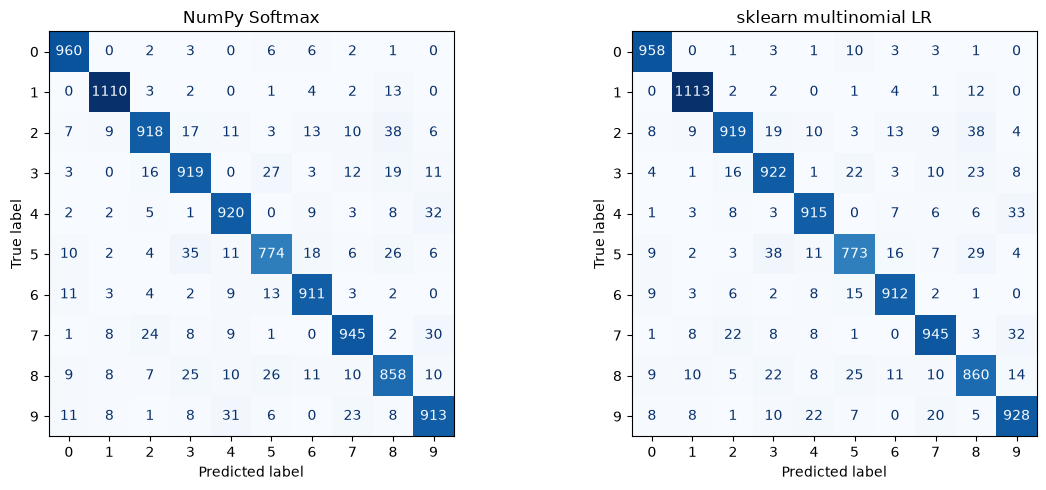

NumPy Softmax
              precision    recall  f1-score   support

           0     0.9467    0.9796    0.9629       980
           1     0.9652    0.9780    0.9716      1135
           2     0.9329    0.8895    0.9107      1032
           3     0.9010    0.9099    0.9054      1010
           4     0.9191    0.9369    0.9279       982
           5     0.9032    0.8677    0.8851       892
           6     0.9344    0.9509    0.9426       958
           7     0.9301    0.9193    0.9247      1028
           8     0.8800    0.8809    0.8805       974
           9     0.9058    0.9049    0.9053      1009

    accuracy                         0.9228     10000
   macro avg     0.9218    0.9218    0.9217     10000
weighted avg     0.9227    0.9228    0.9226     10000

sklearn multinomial LR
              precision    recall  f1-score   support

           0     0.9513    0.9776    0.9643       980
           1     0.9620    0.9806    0.9712      1135
           2     0.9349    0.8905    0.91

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=np.arange(10),
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()
for name, pred in predictions.items():
    print(name)
    print(classification_report(y_test, pred, digits=4, zero_division=0))

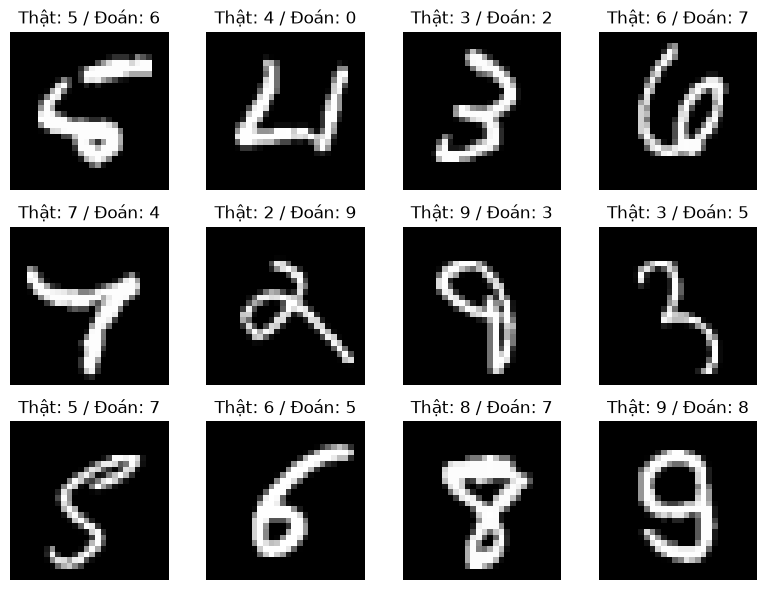

In [9]:
# Quan sát tối đa 12 ảnh bản tay phân loại sai.
wrong = np.flatnonzero(predictions['NumPy Softmax'] != y_test)[:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(8, 6))
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
        ax.set_title(f'Thật: {y_test[i]} / Đoán: {predictions["NumPy Softmax"][i]}')
    plt.tight_layout()
    plt.show()
else:
    print('Không có ảnh sai trong tập test.')


## 4. Nhận xét dựa trên kết quả thực chạy

Không kết luận thư viện “tốt hơn về bản chất mô hình” chỉ vì accuracy cao hơn. Cả hai là softmax tuyến tính; khác optimizer, tiêu chí dừng và mức hội tụ. Bản tay trả checkpoint validation tốt nhất; thư viện trả nghiệm cuối.

- So accuracy và F1 macro; xem lớp nào thường nhầm qua confusion matrix.
- Nếu train CE còn giảm mạnh ở epoch cuối, SGD có thể chưa hội tụ; thử tăng epochs hoặc điều chỉnh learning rate bằng validation.
- Nếu validation CE tăng trong khi train CE giảm, xem xét overfitting và L2.
- Nếu có cảnh báo hội tụ của thư viện, phải ghi rõ trước khi kết luận.
- Softmax không có lớp ẩn và không trực tiếp khai thác cấu trúc không gian ảnh.

Tham khảo API: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html


In [11]:
# Lưu kết quả; chạy lại sẽ thay thế các file cùng tên.
OUTPUT = ROOT / 'results' / 'softmax'
OUTPUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUTPUT / 'comparison.csv')
pd.DataFrame(manual.history_).to_csv(OUTPUT / 'history.csv', index=False)
np.savez_compressed(OUTPUT / 'manual_weights.npz', W=manual.W_, b=manual.b_)
print('Đã lưu:', OUTPUT)


Đã lưu: d:\midterm_pattern_recognition\mnist-pattern-recognition\results\softmax
